# PACE Framework: Plan Stage
**Business Scenario & Objective:**
The marketing department is looking to launch a global influencer campaign. However, they are unsure how to identify the most valuable creators. Mega-celebrities are expensive, but do they actually guarantee high audience interaction? 
Our goal in this project is to analyze a dataset of top Instagram influencers, perform data cleaning, and use analytical models to segment them into actionable business categories.

In this **Plan Stage**, we will:
1. Load the raw data.
2. Gather basic information and understand the variables.
3. Clean the dataset (fix column names, convert string metrics to numbers, and handle missing data).


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean aesthetic for our plots
sns.set_theme(style="whitegrid")

# 1. Load the raw dataset
df = pd.read_csv('../data/raw/instagram_influencers.csv')

# Let's take a look at the first few rows to understand the structure
display(df.head())

# Gather descriptive statistics and data types
display(df.info())


,Influencer insta name,instagram name,category_1,category_2,Followers,Audience country(mostly),Authentic engagement\r\n,Engagement avg\r\n
0,433,433,Sports with a ball,NaN,48.5M,Spain,383.1K,637K
1,__youngbae__,TAEYANG,Music,NaN,12.7M,Indonesia,478K,542.3K
2,_agentgirl_,НАСТЯ ИВЛЕЕВА,Shows,NaN,18.8M,Russia,310.8K,377.9K
3,_imyour_joy,Joy,Lifestyle,NaN,13.5M,Indonesia,1.1M,1.4M
4,_jeongjaehyun,Jaehyun,NaN,NaN,11.1M,Indonesia,2.5M,3.1M


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Influencer insta name     1000 non-null   str  
 1   instagram name            979 non-null    str  
 2   category_1                892 non-null    str  
 3   category_2                287 non-null    str  
 4   Followers                 1000 non-null   str  
 5   Audience country(mostly)  986 non-null    str  
 6   Authentic engagement
    1000 non-null   str  
 7   Engagement avg
          1000 non-null   str  
dtypes: str(8)
memory usage: 125.7 KB


None

In [20]:
# 2. Data Cleaning: Column Names
# Initial Observation: The column names contain spaces, uppercase letters, and hidden newline characters (like '\r\n').
# We need to standardize them to 'snake_case' for easier coding.
df.columns = (df.columns
                .str.replace(r'\n|\r', '', regex=True)
                .str.strip()
                .str.replace(' ', '_')
                .str.lower())

print("Standardized Column Names:")
print(df.columns.tolist())


Standardized Column Names:
['influencer_insta_name', 'instagram_name', 'category_1', 'category_2', 'followers', 'audience_country(mostly)', 'authentic_engagement', 'engagement_avg']


In [21]:
# 3. Data Cleaning: Numeric Conversions
# Initial Observation: 'followers' and 'engagement_avg' are stored as strings (objects) because they contain 'M' (Millions) and 'K' (Thousands).
# We must convert these to actual floating-point numbers to perform statistical analysis.

def convert_to_number(val):
    if pd.isna(val):
        return val
    val = str(val).upper().replace(',', '')
    if 'M' in val:
        return float(val.replace('M', '')) * 1000000
    elif 'K' in val:
        return float(val.replace('K', '')) * 1000
    else:
        return float(val)

# Explicitly rename columns just in case invisible characters persisted
df.rename(columns={
    'authentic_engagement\r\n': 'authentic_engagement',
    'engagement_avg\r\n': 'engagement_avg'
}, inplace=True, errors='ignore')

cols_to_convert = ['followers', 'authentic_engagement', 'engagement_avg']
for col in cols_to_convert:
    if col in df.columns:
        df[col] = df[col].apply(convert_to_number)

# Verify the transformations
display(df.head(3))


,influencer_insta_name,instagram_name,category_1,category_2,followers,audience_country(mostly),authentic_engagement,engagement_avg
0,433,433,Sports with a ball,NaN,48500000.0,Spain,383100.0,637000.0
1,__youngbae__,TAEYANG,Music,NaN,12700000.0,Indonesia,478000.0,542300.0
2,_agentgirl_,НАСТЯ ИВЛЕЕВА,Shows,NaN,18800000.0,Russia,310800.0,377900.0


In [22]:
# 4. Data Cleaning: Missing Values and Duplicates
print("Missing values per column:")
display(df.isna().sum())

# Observation: 'category_2' is missing over 70% of its data. 'category_1' and 'audience_country' have minor missing values.
# Instead of dropping valuable rows, we will impute categorical missing values with the label 'Unknown'.

df['category_1'] = df['category_1'].fillna('Unknown')
df['category_2'] = df['category_2'].fillna('Unknown')
df['audience_country(mostly)'] = df['audience_country(mostly)'].fillna('Unknown')
df['instagram_name'] = df['instagram_name'].fillna('Unknown')

# Check and drop duplicate rows
duplicates = df.duplicated().sum()
print(f"\nFound {duplicates} duplicate rows. Dropping them...")
df = df.drop_duplicates()

print("Missing values after imputation:")
display(df.isna().sum())


Missing values per column:


influencer_insta_name         0
instagram_name               21
category_1                  108
category_2                  713
followers                     0
audience_country(mostly)     14
authentic_engagement          0
engagement_avg                0
dtype: int64


Found 0 duplicate rows. Dropping them...
Missing values after imputation:


influencer_insta_name       0
instagram_name              0
category_1                  0
category_2                  0
followers                   0
audience_country(mostly)    0
authentic_engagement        0
engagement_avg              0
dtype: int64

# PACE Framework: Analyze Stage
**Objective:** Perform Exploratory Data Analysis (EDA) to uncover relationships between variables.

*Key Questions:*
- How are followers distributed? Is it a normal distribution or skewed?
- Are there extreme outliers in engagement?
- Does having more followers automatically translate to higher average engagement?


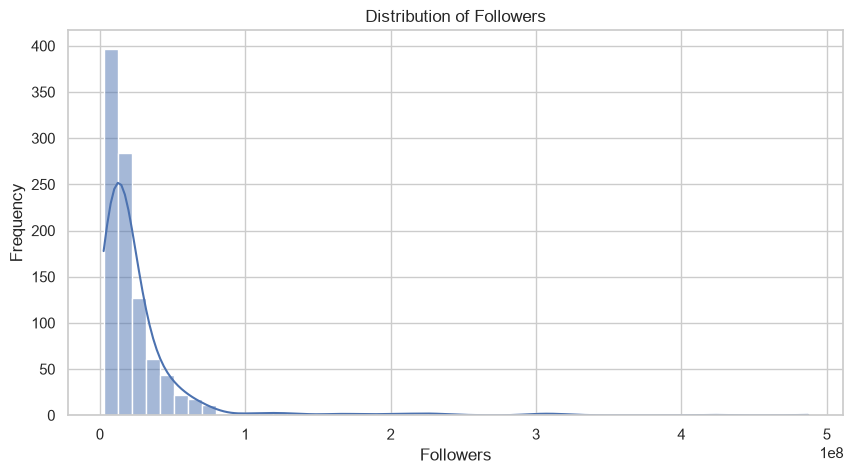

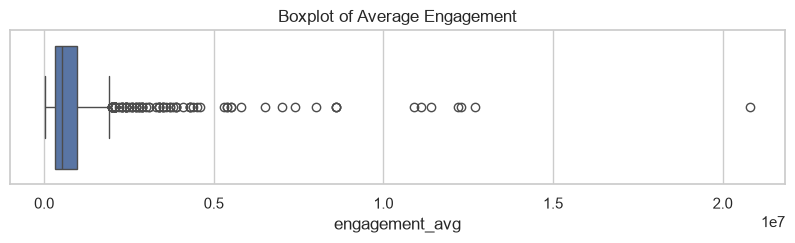

In [23]:
# Distribution of Followers
# We use a histogram to visualize the spread of followers.
plt.figure(figsize=(10, 5))
sns.histplot(df['followers'], bins=50, kde=True)
plt.title('Distribution of Followers')
plt.xlabel('Followers')
plt.ylabel('Frequency')
plt.show()

# Insight: The distribution is heavily right-skewed. The vast majority of influencers have under 50 Million followers, 
# while a long tail extends towards 500 Million (Mega-Celebrities).

# Detecting Outliers in Average Engagement
plt.figure(figsize=(10, 2))
sns.boxplot(x=df['engagement_avg'])
plt.title('Boxplot of Average Engagement')
plt.show()

# Insight: The boxplot shows the interquartile range squished far to the left. The dots stretching to the right are extreme outliers 
# indicating rare accounts with phenomenally high engagement.


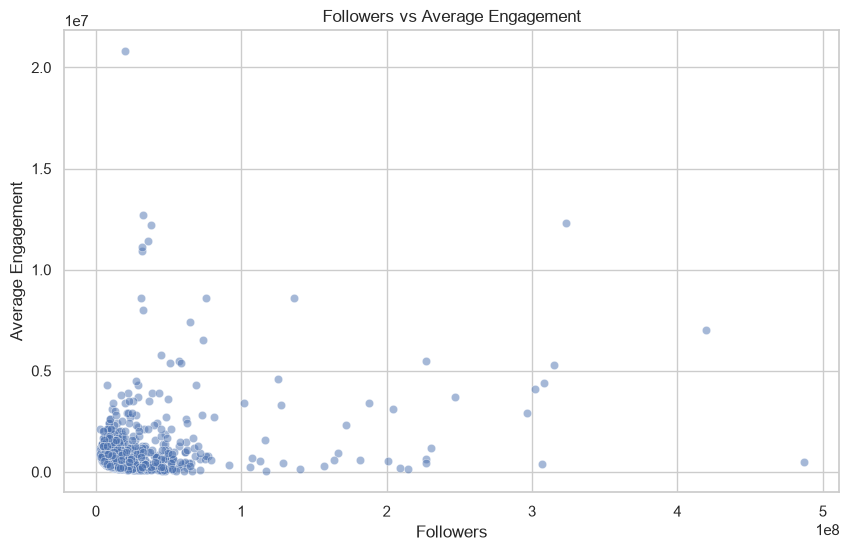

In [24]:
# Relationship between Followers and Average Engagement
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='followers', y='engagement_avg', alpha=0.5)
plt.title('Followers vs Average Engagement')
plt.xlabel('Followers')
plt.ylabel('Average Engagement')
plt.show()

# Insight: There is NO strong linear correlation. The influencer with the highest engagement (~20M) only has around 40M followers. 
# Conversely, the account with 500M followers has near-zero relative engagement. 
# Conclusion: Raw numbers are misleading. We must calculate a normalized metric: the 'Engagement Rate'.


# PACE Framework: Construct Stage
**Objective:** Engineer new features and build analytical models.

1. **Feature Engineering:** We will calculate the `engagement_rate`.
2. **Segmentation Model:** We will use a Machine Learning algorithm called **K-Means Clustering** to segment influencers into 4 distinct business categories based on their followers and engagement rate.

*Crucial Note on Machine Learning:* Because 'followers' are in the tens of millions, while 'engagement_rate' is a small decimal (e.g., 0.05), the K-Means distance calculation would be completely dominated by the followers axis. To fix this, we MUST use a `StandardScaler` to normalize the data before clustering, ensuring both metrics carry equal weight.


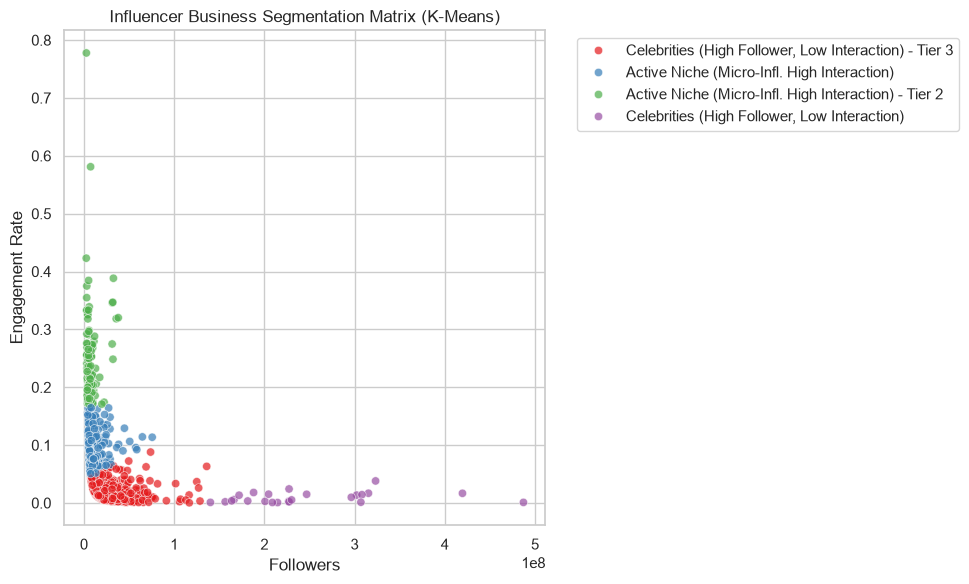

Number of Influencers per Segment:


Segmento
Celebrities (High Follower, Low Interaction) - Tier 3    563
Active Niche (Micro-Infl. High Interaction)              306
Active Niche (Micro-Infl. High Interaction) - Tier 2     106
Celebrities (High Follower, Low Interaction)              24
Name: count, dtype: int64

In [25]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Feature Engineering: Engagement Rate
df['engagement_rate'] = df['engagement_avg'] / df['followers']

# Remove extreme outliers that might be data anomalies (Engagement Rate > 100%)
df_model = df[df['engagement_rate'] <= 1.0].copy()

# 2. Machine Learning: K-Means Clustering
# We will segment the influencers into 4 clusters.
X = df_model[['followers', 'engagement_rate']]

# CRITICAL FIX: Standardize the features! 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize and fit the K-Means model on the SCALED data
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_model['cluster'] = kmeans.fit_predict(X_scaled)

# Map the generic cluster numbers to business segments.
# We determine the "personality" of each cluster by looking at its median values.
cluster_summary = df_model.groupby('cluster')[['followers', 'engagement_rate']].median()
followers_median = df_model['followers'].median()
er_median = df_model['engagement_rate'].median()

mapping = {}
for cluster_id, row in cluster_summary.iterrows():
    if row['followers'] > followers_median and row['engagement_rate'] > er_median:
        mapping[cluster_id] = 'Stars (High Follower, High Interaction)'
    elif row['followers'] > followers_median and row['engagement_rate'] <= er_median:
        mapping[cluster_id] = 'Celebrities (High Follower, Low Interaction)'
    elif row['followers'] <= followers_median and row['engagement_rate'] > er_median:
        mapping[cluster_id] = 'Active Niche (Micro-Infl. High Interaction)'
    else:
        mapping[cluster_id] = 'Low Potential (Micro-Infl. Low Interaction)'

# If the algorithm found multiple clusters in the same "business quadrant", 
# we append the cluster ID to keep them distinct.
unique_mapping = {}
used_names = set()
for c_id, name in mapping.items():
    if name in used_names:
        unique_mapping[c_id] = f"{name} - Tier {c_id}"
    else:
        unique_mapping[c_id] = name
        used_names.add(name)

df_model['Segmento'] = df_model['cluster'].map(unique_mapping)

# Visualize the Segmentation Matrix
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_model, x='followers', y='engagement_rate', hue='Segmento', palette='Set1', alpha=0.7)
plt.title('Influencer Business Segmentation Matrix (K-Means)')
plt.xlabel('Followers')
plt.ylabel('Engagement Rate')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("Number of Influencers per Segment:")
display(df_model['Segmento'].value_counts())


# PACE Framework: Execute Stage
**Objective:** Interpret results, summarize key insights for stakeholders, and export the finalized dataset for the interactive Streamlit Dashboard.

*Key Business Recommendations:*
- **Active Niche Creators** are highly valuable: they are likely cheaper to sponsor but yield excellent engagement rates.
- **Celebrities** should be used strictly for broad Brand Awareness, not for direct conversion or high-engagement campaigns.
- Further geospatial analysis and Bot Detection will be handled dynamically in the Streamlit application.


In [26]:
# Select only the relevant columns for our Dashboard to optimize memory and speed
final_columns = [
    'influencer_insta_name', 'instagram_name', 'category_1', 
    'followers', 'audience_country(mostly)', 'authentic_engagement', 
    'engagement_avg', 'engagement_rate', 'Segmento'
]
df_final = df_model[final_columns]

# Export the clean, enriched dataset
df_final.to_csv('../data/processed/influencers_segmented.csv', index=False)
print("Data successfully exported to data/processed/influencers_segmented.csv!")
print("The data is now ready to be consumed by the Streamlit Dashboard (src/app.py).")


Data successfully exported to data/processed/influencers_segmented.csv!
The data is now ready to be consumed by the Streamlit Dashboard (src/app.py).
